# CNN Binary Image Classification: Deer vs Horse

Notebook ini mencakup:
1. Dataset Exploration
2. Data Preprocessing (tanpa data augmentation)
3. Building a CNN Model
4. Model Training
5. Model Evaluation
6. Visualization of Results (termasuk fungsi prediksi dengan input gambar *live*)

## 0. Setup

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from PIL import Image, ImageFilter

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Input, Conv2D, MaxPooling2D, Flatten, Dense,
                                     Dropout, BatchNormalization, GlobalAveragePooling2D)
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Konfigurasi
DATASET_PATH = '../demo'          # ubah jika lokasi dataset berbeda
classes = ['deer', 'horse']
splits = ['train', 'test']
IMAGE_EXTS = ('.jpg', '.jpeg', '.png', '.bmp')
IMAGE_SIZE = (32, 32)
BATCH_SIZE = 32
VALIDATION_SPLIT = 0.2

# Parameter contrast enhancement (contrast stretching berbasis persentil)
CONTRAST_CUTOFF = 1      # abaikan 1% piksel tergelap & 1% terterang saat meregangkan kontras

# Parameter sharpening (Unsharp Mask)
SHARPEN_RADIUS = 1
SHARPEN_PERCENT = 150
SHARPEN_THRESHOLD = 2

assert os.path.isdir(DATASET_PATH), (
    f"Folder dataset '{DATASET_PATH}' tidak ditemukan. "
    "Pastikan struktur: <DATASET_PATH>/train|test/deer|horse"
)

## 1. Dataset Exploration

### 1.1 Load dataset & cek ukuran dataset

In [2]:
def list_images(split, class_name):
    folder = os.path.join(DATASET_PATH, split, class_name)
    return sorted(f for f in os.listdir(folder) if f.lower().endswith(IMAGE_EXTS))

print("===== DATASET SIZE =====")
totals = {}
for split in splits:
    print(f"\n--- {split.upper()} DATASET ---")
    totals[split] = 0
    for class_name in classes:
        n = len(list_images(split, class_name))
        totals[split] += n
        print(f"{class_name}: {n} images")
    print(f"Total {split} images: {totals[split]}")

print("\n--- OVERALL DATASET ---")
print(f"Total Images: {sum(totals.values())}")

===== DATASET SIZE =====

--- TRAIN DATASET ---
deer: 500 images
horse: 500 images
Total train images: 1000

--- TEST DATASET ---
deer: 250 images
horse: 250 images
Total test images: 500

--- OVERALL DATASET ---
Total Images: 1500


### 1.2 Distribusi kelas

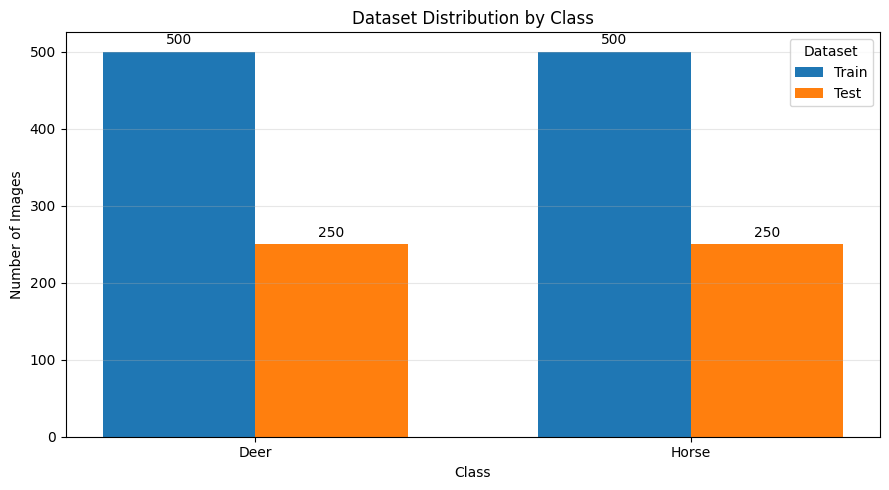

In [3]:
distribution = {s: [len(list_images(s, c)) for c in classes] for s in splits}

x = np.arange(len(classes))
width = 0.35

plt.figure(figsize=(9, 5))
for i, split in enumerate(splits):
    offset = (i - (len(splits) - 1) / 2) * width
    bars = plt.bar(x + offset, distribution[split], width, label=split.capitalize())
    plt.bar_label(bars, padding=3)

plt.title('Dataset Distribution by Class')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks(x, [c.capitalize() for c in classes])
plt.legend(title='Dataset')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1.3 Dimensi gambar, mode warna, dan statistik piksel

In [4]:
for split in splits:
    dims, modes, pixel_sum, pixel_sq, pixel_cnt = Counter(), Counter(), 0.0, 0.0, 0
    pmin, pmax = 255, 0

    for class_name in classes:
        for fname in list_images(split, class_name):
            with Image.open(os.path.join(DATASET_PATH, split, class_name, fname)) as img:
                dims[img.size] += 1
                modes[img.mode] += 1
                arr = np.asarray(img, dtype=np.float64)
                pixel_sum += arr.sum()
                pixel_sq += (arr ** 2).sum()
                pixel_cnt += arr.size
                pmin, pmax = min(pmin, arr.min()), max(pmax, arr.max())

    mean = pixel_sum / pixel_cnt
    std = np.sqrt(pixel_sq / pixel_cnt - mean ** 2)

    print(f"===== {split.upper()} =====")
    print("Image sizes :", dict(dims))
    print("Color modes :", dict(modes))
    print(f"Pixel min/max: {pmin:.0f} / {pmax:.0f}")
    print(f"Pixel mean/std: {mean:.2f} / {std:.2f}\n")

===== TRAIN =====
Image sizes : {(32, 32): 1000}
Color modes : {'RGB': 1000}
Pixel min/max: 0 / 255
Pixel mean/std: 115.36 / 58.82

===== TEST =====
Image sizes : {(32, 32): 500}
Color modes : {'RGB': 500}
Pixel min/max: 0 / 255
Pixel mean/std: 113.13 / 57.78



### 1.4 Visualisasi 5 contoh gambar dari setiap kelas

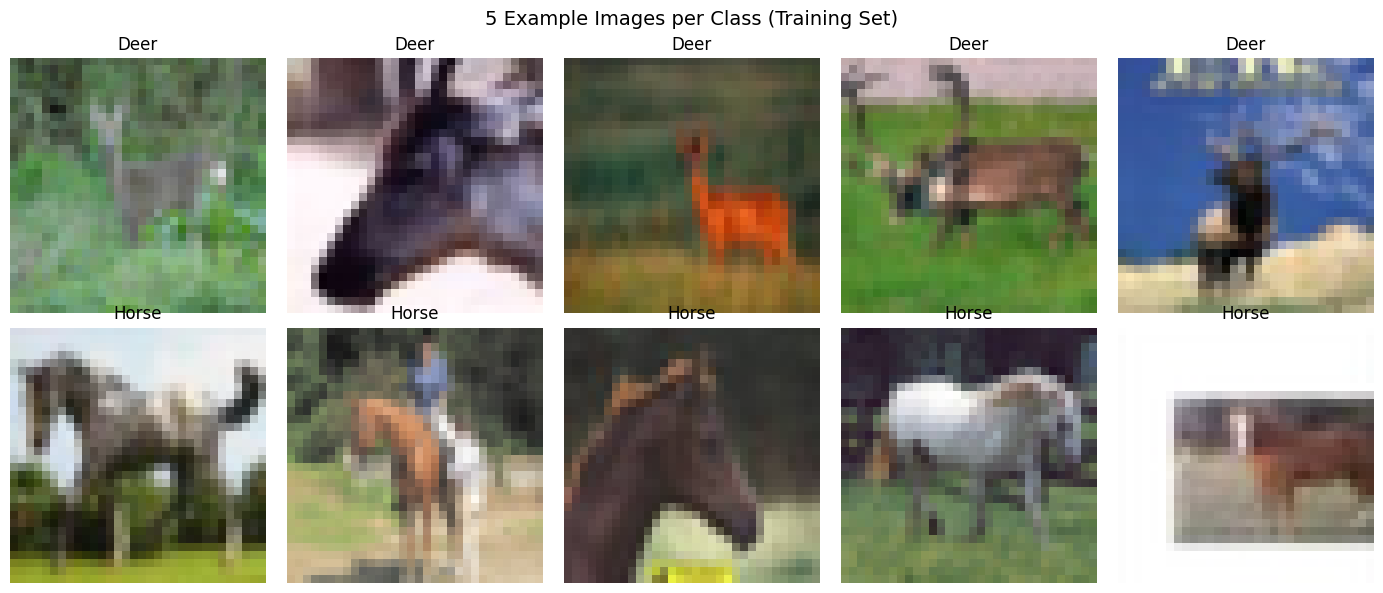

In [5]:
fig, axes = plt.subplots(len(classes), 5, figsize=(14, 6))

for r, class_name in enumerate(classes):
    files = list_images('train', class_name)
    chosen = random.Random(SEED).sample(files, 5)   # 5 gambar acak (reproducible)
    for c, fname in enumerate(chosen):
        img = Image.open(os.path.join(DATASET_PATH, 'train', class_name, fname)).convert('RGB')
        axes[r, c].imshow(img)
        axes[r, c].set_title(class_name.capitalize())
        axes[r, c].axis('off')

plt.suptitle('5 Example Images per Class (Training Set)', fontsize=14)
plt.tight_layout()
plt.show()

## 2. Data Preprocessing

Langkah preprocessing (**tanpa data augmentation**):
- Memuat gambar sebagai **RGB** dan memastikan ukuran seragam **32×32**
- **Contrast Enhancement** (contrast stretching): merentangkan histogram piksel ke rentang penuh 0-255 agar gambar yang terlalu gelap/pucat lebih jelas. Dilakukan pada seluruh kanal sekaligus sehingga rasio warna (hue) tidak berubah
- **Sharpening** (Unsharp Mask) untuk mempertegas tepi/detail gambar. Ini deterministik (diterapkan sama ke semua gambar), sehingga **bukan** augmentation. Contrast enhancement dan sharpening sama-sama deterministik
- **Normalisasi** piksel dari [0, 255] menjadi [0, 1] (`rescale = 1/255`)
- Label biner: `deer = 0`, `horse = 1`
- Memisahkan data train menjadi **80% training / 20% validation**
- Data test diproses dengan contrast enhancement + sharpening + normalisasi yang sama (tidak diacak, agar urutan label konsisten)

In [6]:
def sharpen_array(x):
    """Sharpening (Unsharp Mask) pada array float 0-255 berukuran (H, W, 3).
    Dipanggil SEBELUM rescale, sehingga outputnya tetap 0-255."""
    img = Image.fromarray(np.clip(x, 0, 255).astype('uint8'))
    img = img.filter(ImageFilter.UnsharpMask(radius=SHARPEN_RADIUS,
                                             percent=SHARPEN_PERCENT,
                                             threshold=SHARPEN_THRESHOLD))
    return np.asarray(img, dtype='float32')

def enhance_contrast_array(x):
    """Contrast stretching pada array float 0-255 (H, W, 3).
    Piksel diregangkan dari [persentil bawah, persentil atas] menjadi [0, 255].
    Satu rentang untuk semua kanal -> rasio warna terjaga."""
    x = x.astype('float32')
    lo, hi = np.percentile(x, [CONTRAST_CUTOFF, 100 - CONTRAST_CUTOFF])
    if hi - lo < 1:                      # gambar hampir rata -> jangan diubah
        return x
    return np.clip((x - lo) / (hi - lo) * 255.0, 0, 255)


def preprocess_array(x):
    """Pipeline preprocessing: contrast enhancement -> sharpening (output tetap 0-255)."""
    return sharpen_array(enhance_contrast_array(x))


# Contrast enhancement + sharpening + rescale, TANPA augmentation
# (tidak ada flip/rotation/zoom/shift, dll.)
# Urutan di Keras: preprocessing_function -> rescale (/255)
train_datagen = ImageDataGenerator(preprocessing_function=preprocess_array,
                                   rescale=1./255, validation_split=VALIDATION_SPLIT)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_array, rescale=1./255)

common = dict(target_size=IMAGE_SIZE, batch_size=BATCH_SIZE,
              class_mode='binary', color_mode='rgb')

train_generator = train_datagen.flow_from_directory(
    f'{DATASET_PATH}/train', subset='training', shuffle=True, seed=SEED, **common)

validation_generator = train_datagen.flow_from_directory(
    f'{DATASET_PATH}/train', subset='validation', shuffle=False, **common)

test_generator = test_datagen.flow_from_directory(
    f'{DATASET_PATH}/test', shuffle=False, **common)

print("\nClass Mapping:", train_generator.class_indices)
class_names = [k for k, v in sorted(train_generator.class_indices.items(), key=lambda kv: kv[1])]

Found 800 images belonging to 2 classes.
Found 200 images belonging to 2 classes.
Found 500 images belonging to 2 classes.

Class Mapping: {'deer': 0, 'horse': 1}


### Visualisasi hasil preprocessing (original → contrast enhancement → + sharpening)

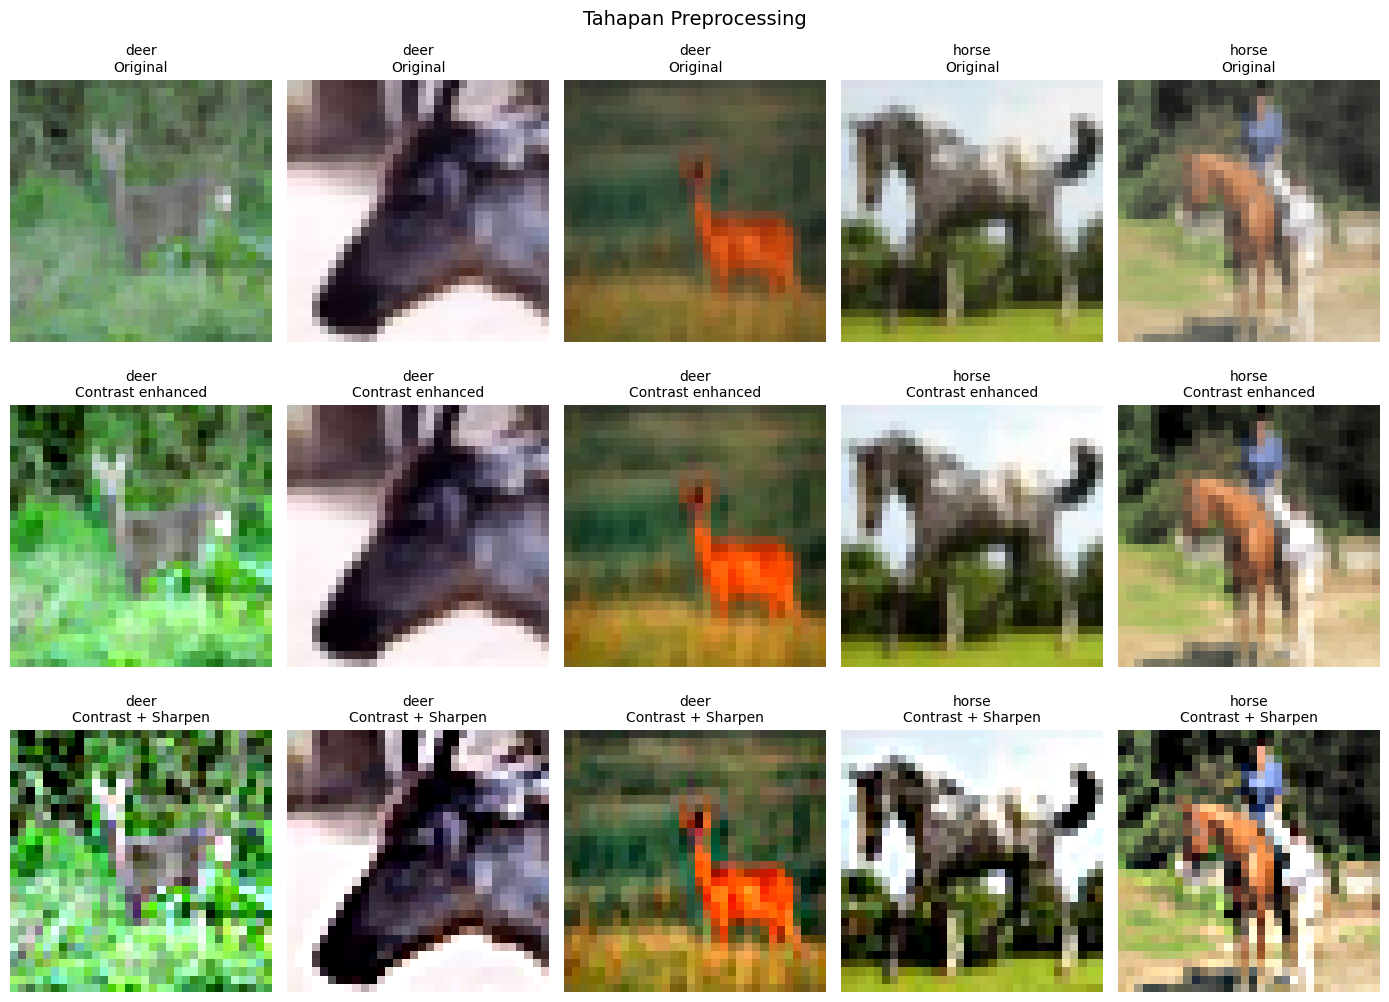

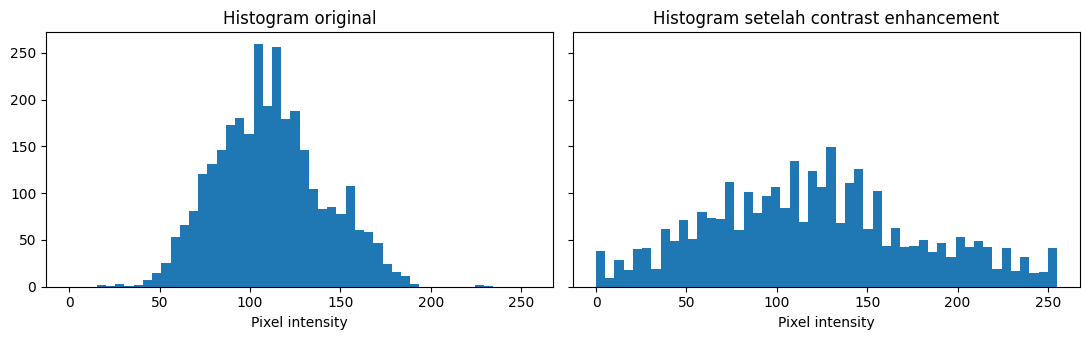

In [7]:
# 3 gambar deer + 2 gambar horse
samples = [('deer', f) for f in random.Random(SEED).sample(list_images('train', 'deer'), 3)] + \
          [('horse', f) for f in random.Random(SEED).sample(list_images('train', 'horse'), 2)]

fig, axes = plt.subplots(3, 5, figsize=(14, 10.5))
row_titles = ['Original', 'Contrast enhanced', 'Contrast + Sharpen']

for col, (class_name, fname) in enumerate(samples):
    raw = np.asarray(Image.open(os.path.join(DATASET_PATH, 'train', class_name, fname)).convert('RGB'), dtype='float32')
    contrast = enhance_contrast_array(raw)
    both = preprocess_array(raw)
    for row, im in enumerate([raw, contrast, both]):
        axes[row, col].imshow(im.astype('uint8'))
        axes[row, col].set_title(f'{class_name}\n{row_titles[row]}', fontsize=10)
        axes[row, col].axis('off')

plt.suptitle('Tahapan Preprocessing', fontsize=14)
plt.tight_layout()
plt.show()

# Histogram sebelum vs sesudah contrast enhancement (gambar pertama)
class_name, fname = samples[0]
raw = np.asarray(Image.open(os.path.join(DATASET_PATH, 'train', class_name, fname)).convert('RGB'), dtype='float32')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
ax[0].hist(raw.flatten(), bins=50, range=(0, 255));                        ax[0].set_title('Histogram original')
ax[1].hist(enhance_contrast_array(raw).flatten(), bins=50, range=(0, 255)); ax[1].set_title('Histogram setelah contrast enhancement')
for a_ in ax: a_.set_xlabel('Pixel intensity')
plt.tight_layout()
plt.show()

### Verifikasi normalisasi

Batch shape : (32, 32, 32, 3)
Label shape : (32,)
Pixel range : 0.000 - 1.000  (harus berada dalam 0 - 1)


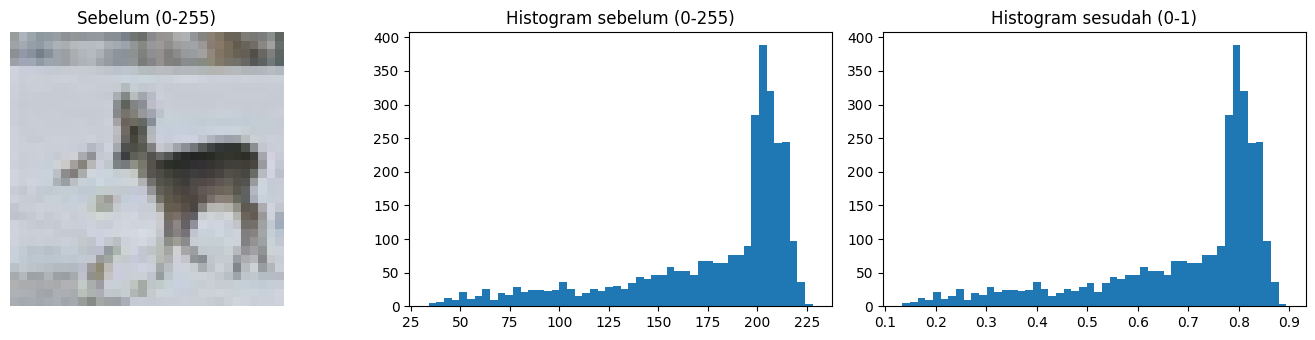

In [8]:
images, labels = next(train_generator)
print("Batch shape :", images.shape)
print("Label shape :", labels.shape)
print(f"Pixel range : {images.min():.3f} - {images.max():.3f}  (harus berada dalam 0 - 1)")

# Perbandingan sebelum vs sesudah normalisasi untuk satu gambar
raw_path = os.path.join(DATASET_PATH, 'train', 'deer', list_images('train', 'deer')[0])
raw = np.asarray(Image.open(raw_path).convert('RGB'))
norm = raw / 255.0

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].imshow(raw);  ax[0].set_title('Sebelum (0-255)'); ax[0].axis('off')
ax[1].hist(raw.flatten(), bins=50);  ax[1].set_title('Histogram sebelum (0-255)')
ax[2].hist(norm.flatten(), bins=50); ax[2].set_title('Histogram sesudah (0-1)')
plt.tight_layout()
plt.show()

## 3. Building a CNN Model

Pada bagian ini dibuat **4 versi arsitektur CNN** untuk eksplorasi. Semuanya memuat komponen wajib: *Convolution, Pooling, Fully Connected, dan output layer dengan sigmoid*.

| Versi | Ide utama |
|---|---|
| **V1 – Baseline** | 2 blok Conv+Pool → Flatten → Dense(64) → sigmoid (model awal) |
| **V2 – Baseline + Dropout** | Sama seperti V1, ditambah Dropout(0.5) untuk mengurangi overfitting |
| **V3 – BatchNorm + 3 blok** | `padding='same'`, BatchNormalization (`momentum=0.9`, cocok untuk dataset kecil), 3 blok Conv+Pool (32→64→128), Dropout(0.5) |
| **V4 – Double Conv + GAP** | Gaya VGG kecil: 2 Conv per blok, BatchNorm, `GlobalAveragePooling2D` (parameter jauh lebih sedikit di bagian FC), Dropout(0.4) |

In [9]:
def build_v1():
    # V1 - Baseline
    return Sequential([
        Input(shape=(32, 32, 3)),
        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ], name='V1_Baseline')


def build_v2():
    # V2 - Baseline + Dropout
    return Sequential([
        Input(shape=(32, 32, 3)),
        Conv2D(32, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), activation='relu'),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ], name='V2_Dropout')


def build_v3():
    # V3 - BatchNorm + padding same + 3 blok Conv/Pool
    return Sequential([
        Input(shape=(32, 32, 3)),
        Conv2D(32, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        MaxPooling2D((2, 2)),
        Flatten(),
        Dense(64, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ], name='V3_BatchNorm_3Blocks')


def build_v4():
    # V4 - Double Conv per blok + BatchNorm + GlobalAveragePooling
    return Sequential([
        Input(shape=(32, 32, 3)),
        Conv2D(32, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        Conv2D(32, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        MaxPooling2D((2, 2)),
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        Conv2D(64, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        MaxPooling2D((2, 2)),
        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(momentum=0.9),
        GlobalAveragePooling2D(),
        Dense(64, activation='relu'),
        Dropout(0.4),
        Dense(1, activation='sigmoid')
    ], name='V4_DoubleConv_GAP')


MODEL_BUILDERS = {
    'V1 Baseline': build_v1,
    'V2 Dropout': build_v2,
    'V3 BatchNorm+3Blocks': build_v3,
    'V4 DoubleConv+GAP': build_v4,
}

for name, builder in MODEL_BUILDERS.items():
    m = builder()
    print(f"{name:<24} -> {m.count_params():>9,} parameter")

V1 Baseline              ->   166,977 parameter
V2 Dropout               ->   166,977 parameter
V3 BatchNorm+3Blocks     ->   225,345 parameter
V4 DoubleConv+GAP        ->   149,025 parameter


## 4. Model Training

- **Loss function**: Binary Crossentropy (cocok untuk output sigmoid & 2 kelas)
- **Optimizer**: Adam (learning rate default 0.001)
- **Early stopping** pada `val_loss` (patience = 3, `restore_best_weights=True`)
- Keempat versi dilatih dengan **pengaturan yang sama** (data, epoch maksimum, seed) agar perbandingannya adil.
- Model terbaik dipilih berdasarkan **validation loss terendah** (bukan data test, agar test tetap bersih untuk evaluasi akhir).

In [10]:
EPOCHS = 20

trained, histories, rows = {}, {}, []

for name, builder in MODEL_BUILDERS.items():
    print(f"\n========== Training {name} ==========")
    tf.keras.utils.set_random_seed(SEED)           # seed sama untuk tiap versi
    m = builder()

    m.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

    h = m.fit(
        train_generator,
        epochs=EPOCHS,
        validation_data=validation_generator,
        callbacks=[early_stopping],
        verbose=2
    )

    best_ep = int(np.argmin(h.history['val_loss']))      # index epoch terbaik (val_loss terendah)

    # Informasi tambahan: hasil pada data test (TIDAK dipakai untuk memilih model)
    test_generator.reset()
    prob = m.predict(test_generator, verbose=0).flatten()
    pred = (prob > 0.5).astype(int)

    trained[name], histories[name] = m, h
    rows.append({
        'Model': name,
        'Params': m.count_params(),
        'Epochs run': len(h.history['loss']),
        'Best epoch': best_ep + 1,
        'Train Acc': h.history['accuracy'][best_ep],
        'Val Acc': h.history['val_accuracy'][best_ep],
        'Val Loss': h.history['val_loss'][best_ep],
        'Gap (Train-Val Acc)': h.history['accuracy'][best_ep] - h.history['val_accuracy'][best_ep],
        'Test Acc': accuracy_score(test_generator.classes, pred),
        'Test F1': f1_score(test_generator.classes, pred, zero_division=0),
    })


========== Training V1 Baseline ==========
Epoch 1/20
25/25 - 3s - 102ms/step - accuracy: 0.5625 - loss: 0.6887 - val_accuracy: 0.5350 - val_loss: 0.6630
Epoch 2/20
25/25 - 1s - 37ms/step - accuracy: 0.6275 - loss: 0.6359 - val_accuracy: 0.7300 - val_loss: 0.5751
Epoch 3/20
25/25 - 1s - 36ms/step - accuracy: 0.7362 - loss: 0.5376 - val_accuracy: 0.7450 - val_loss: 0.5016
Epoch 4/20
25/25 - 1s - 36ms/step - accuracy: 0.7875 - loss: 0.4642 - val_accuracy: 0.8450 - val_loss: 0.4016
Epoch 5/20
25/25 - 1s - 36ms/step - accuracy: 0.8250 - loss: 0.3999 - val_accuracy: 0.8500 - val_loss: 0.3650
Epoch 6/20
25/25 - 1s - 37ms/step - accuracy: 0.8462 - loss: 0.3590 - val_accuracy: 0.7450 - val_loss: 0.4486
Epoch 7/20
25/25 - 1s - 35ms/step - accuracy: 0.8700 - loss: 0.3211 - val_accuracy: 0.8450 - val_loss: 0.3588
Epoch 8/20
25/25 - 1s - 36ms/step - accuracy: 0.8875 - loss: 0.2703 - val_accuracy: 0.8450 - val_loss: 0.3522
Epoch 9/20
25/25 - 1s - 38ms/step - accuracy: 0.9075 - loss: 0.2425 - val_a

### Perbandingan keempat versi

In [11]:
comparison = pd.DataFrame(rows).set_index('Model')
display(comparison.style.format({
    'Params': '{:,}', 'Train Acc': '{:.4f}', 'Val Acc': '{:.4f}', 'Val Loss': '{:.4f}',
    'Gap (Train-Val Acc)': '{:+.4f}', 'Test Acc': '{:.4f}', 'Test F1': '{:.4f}'
}).highlight_min(subset=['Val Loss'], color='#c8e6c9'))

# Pilih model terbaik berdasarkan validation loss
best_name = comparison['Val Loss'].idxmin()
model = trained[best_name]
history = histories[best_name]
print(f"\nModel terbaik (val loss terendah): {best_name}")
model.summary()

,Params,Epochs run,Best epoch,Train Acc,Val Acc,Val Loss,Gap (Train-Val Acc),Test Acc,Test F1
Model,,,,,,,,,
V1 Baseline,"166,977",16,13,0.9712,0.8500,0.3299,+0.1212,0.8040,0.7975
V2 Dropout,"166,977",12,9,0.8825,0.8700,0.3297,+0.0125,0.8060,0.8109
V3 BatchNorm+3Blocks,"225,345",8,5,0.9125,0.8500,0.3686,+0.0625,0.8200,0.8269
V4 DoubleConv+GAP,"149,025",6,3,0.8075,0.8050,0.4196,+0.0025,0.7940,0.7944



Model terbaik (val loss terendah): V2 Dropout


Model: "V2_Dropout"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 500,933 (1.91 MB)

 Trainable params: 166,977 (652.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 333,956 (1.27 MB)

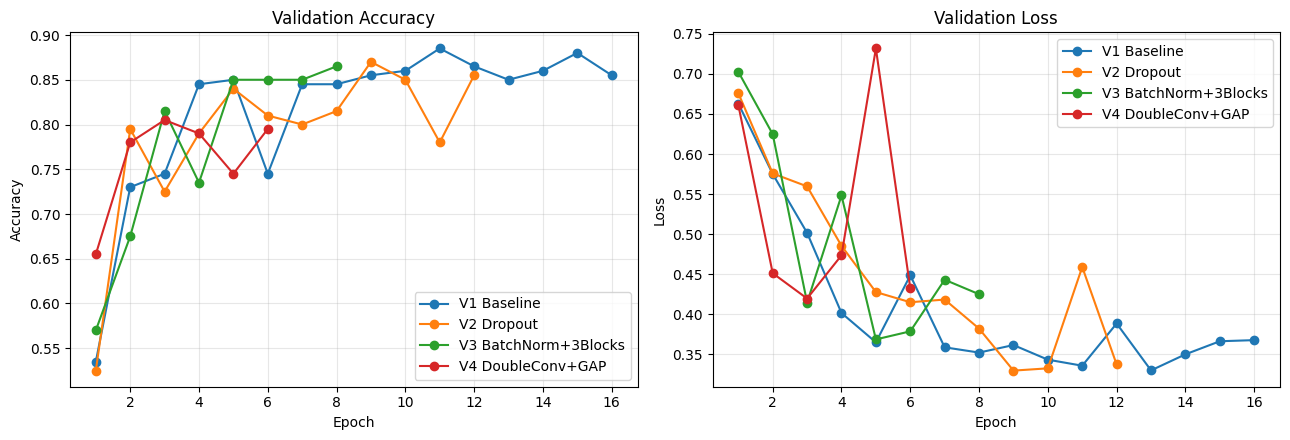

In [12]:
# Kurva validation semua versi
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, h in histories.items():
    ax[0].plot(range(1, len(h.history['val_accuracy']) + 1), h.history['val_accuracy'], marker='o', label=name)
    ax[1].plot(range(1, len(h.history['val_loss']) + 1), h.history['val_loss'], marker='o', label=name)

ax[0].set_title('Validation Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Accuracy')
ax[1].set_title('Validation Loss');     ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Loss')
for a_ in ax:
    a_.grid(alpha=0.3); a_.legend()
plt.tight_layout()
plt.show()

## 5. Model Evaluation

Evaluasi dilakukan pada **model terbaik** hasil eksplorasi di bagian 4.

### 5.1 Menguji model dengan data test

In [13]:
test_loss, test_accuracy = model.evaluate(test_generator, verbose=0)
print(f"Test Loss    : {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Test Loss    : 0.4232
Test Accuracy: 0.8060


### 5.2 Accuracy, Precision, Recall, F1-score

Kelas positif = **horse (1)**, kelas negatif = **deer (0)**.

Accuracy : 0.8060
Precision: 0.7909
Recall   : 0.8320
F1-Score : 0.8109

Classification Report:
              precision    recall  f1-score   support

        deer       0.82      0.78      0.80       250
       horse       0.79      0.83      0.81       250

    accuracy                           0.81       500
   macro avg       0.81      0.81      0.81       500
weighted avg       0.81      0.81      0.81       500



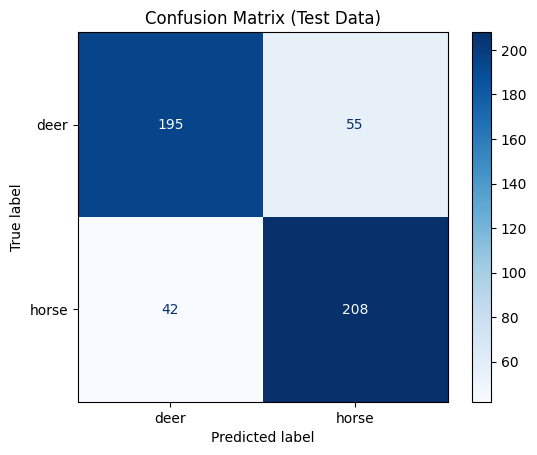

In [14]:
test_generator.reset()
y_true = test_generator.classes
y_prob = model.predict(test_generator, verbose=0).flatten()
y_pred = (y_prob > 0.5).astype(int)

print(f"Accuracy : {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-Score : {f1_score(y_true, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=class_names).plot(cmap='Blues')
plt.title('Confusion Matrix (Test Data)')
plt.show()

## 6. Visualization of Results

### 6.1 Plot loss dan accuracy (training vs validation)

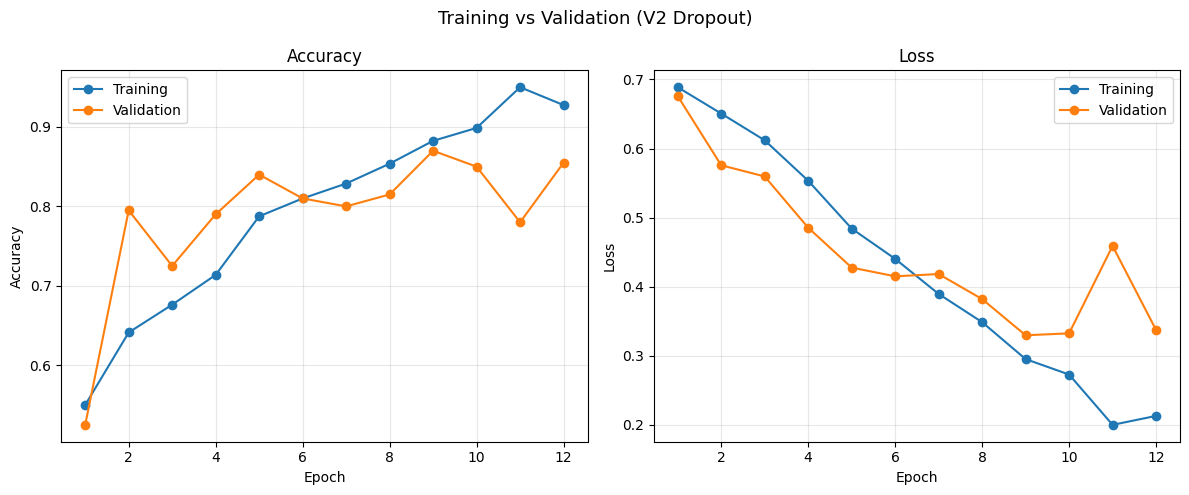

In [15]:
epochs_range = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history['accuracy'], marker='o', label='Training')
plt.plot(epochs_range, history.history['val_accuracy'], marker='o', label='Validation')
plt.title('Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history['loss'], marker='o', label='Training')
plt.plot(epochs_range, history.history['val_loss'], marker='o', label='Validation')
plt.title('Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(alpha=0.3)

plt.suptitle(f'Training vs Validation ({best_name})', fontsize=13)
plt.tight_layout()
plt.show()

### 6.2 Lima gambar dari data test beserta prediksi model dan label aslinya

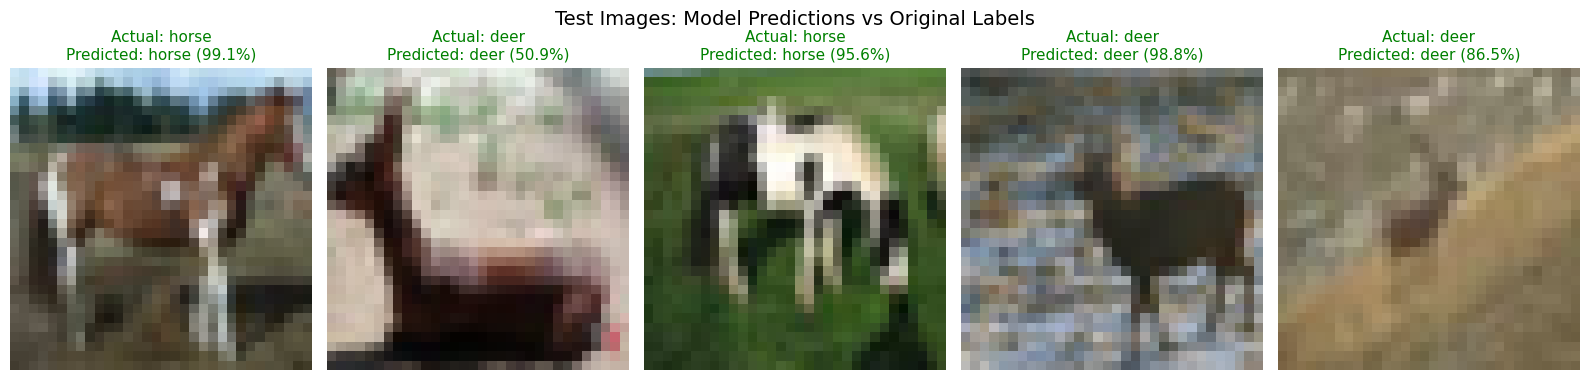

In [16]:
# Ambil 5 gambar acak dari data test (hijau = benar, merah = salah)
rng = np.random.RandomState(SEED)
idx = rng.choice(len(test_generator.filepaths), size=5, replace=False)

fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, i in zip(axes, idx):
    img = Image.open(test_generator.filepaths[i]).convert('RGB')
    pred_label = class_names[y_pred[i]]
    true_label = class_names[y_true[i]]
    conf = y_prob[i] if y_pred[i] == 1 else 1 - y_prob[i]
    correct = pred_label == true_label

    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f"Actual: {true_label}\nPredicted: {pred_label} ({conf:.1%})",
                 color='green' if correct else 'red', fontsize=11)

plt.suptitle('Test Images: Model Predictions vs Original Labels', fontsize=14)
plt.tight_layout()
plt.show()

### 6.3 Fungsi prediksi & input gambar *live*

`predict_image()` menerima **path file**, objek **PIL Image**, **bytes**, atau **numpy array**.
Preprocessing-nya sama persis dengan data training (RGB, resize 32×32, contrast enhancement, sharpening, bagi 255).

> Catatan: model hanya mengenal 2 kelas (deer/horse), jadi gambar lain pun akan dipaksa masuk ke salah satunya.

File: ../demo/test\deer\0004.png | Label asli: deer


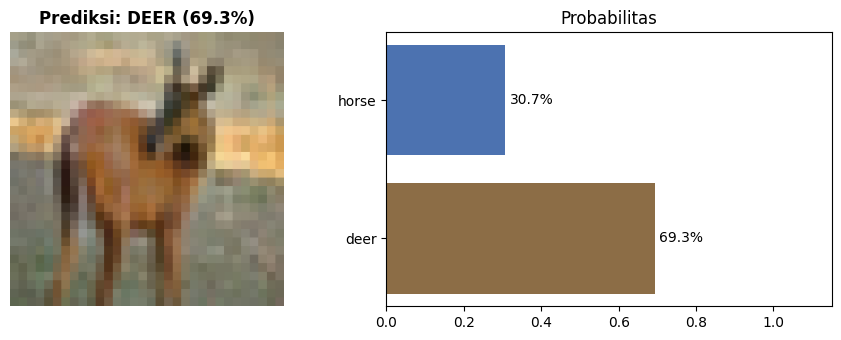

In [17]:
import io

def preprocess_image(source):
    """Ubah input (path / bytes / PIL / ndarray) menjadi array (1, 32, 32, 3) ternormalisasi."""
    if isinstance(source, (str, os.PathLike)):
        img = Image.open(source)
    elif isinstance(source, (bytes, bytearray, memoryview)):
        img = Image.open(io.BytesIO(bytes(source)))
    elif isinstance(source, np.ndarray):
        img = Image.fromarray(source.astype('uint8'))
    elif isinstance(source, Image.Image):
        img = source
    else:
        raise TypeError(f"Tipe input tidak didukung: {type(source)}")

    img = img.convert('RGB').resize(IMAGE_SIZE)          # RGB + 32x32
    arr = preprocess_array(np.asarray(img, dtype='float32'))  # contrast + sharpen (sama dengan training)
    arr = arr / 255.0                                         # normalisasi 0-1
    return np.expand_dims(arr, axis=0), img


def predict_image(source, show=True):
    """Prediksi satu gambar. Mengembalikan (label, confidence)."""
    x, img = preprocess_image(source)
    prob_horse = float(model.predict(x, verbose=0)[0][0])
    prob_deer = 1.0 - prob_horse

    label = class_names[1] if prob_horse > 0.5 else class_names[0]
    confidence = max(prob_horse, prob_deer)

    if show:
        fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), gridspec_kw={'width_ratios': [1, 1.2]})
        ax[0].imshow(img.resize((256, 256), Image.NEAREST))
        ax[0].set_title(f"Prediksi: {label.upper()} ({confidence:.1%})", fontweight='bold')
        ax[0].axis('off')

        bars = ax[1].barh(class_names, [prob_deer, prob_horse], color=['#8c6d46', '#4c72b0'])
        ax[1].bar_label(bars, labels=[f"{prob_deer:.1%}", f"{prob_horse:.1%}"], padding=3)
        ax[1].set_xlim(0, 1.15)
        ax[1].set_title('Probabilitas')
        plt.tight_layout()
        plt.show()

    return label, confidence


# Contoh pemakaian dengan salah satu gambar test
sample_path = test_generator.filepaths[0]
print("File:", sample_path, "| Label asli:", class_names[y_true[0]])
predict_image(sample_path);

#### Input gambar live (pilih salah satu)

**Opsi A – Upload gambar** (Jupyter / VS Code / Colab dengan `ipywidgets`): klik tombol, pilih gambar, hasil prediksi langsung tampil.

In [18]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output

    uploader = widgets.FileUpload(accept='image/*', multiple=False, description='Upload gambar')
    out = widgets.Output()

    def on_upload(change):
        with out:
            clear_output(wait=True)
            val = uploader.value
            # ipywidgets 8: tuple of dict | ipywidgets 7: dict of dict
            item = val[-1] if isinstance(val, (tuple, list)) else list(val.values())[-1]
            print("File:", item['name'])
            predict_image(item['content'])

    uploader.observe(on_upload, names='value')
    display(uploader, out)
except ImportError:
    print("ipywidgets belum terpasang. Jalankan: pip install ipywidgets  (atau gunakan Opsi B)")

ipywidgets belum terpasang. Jalankan: pip install ipywidgets  (atau gunakan Opsi B)


**Opsi B – Masukkan path gambar** secara interaktif (ketik `q` untuk berhenti).

In [19]:
while True:
    path = input("Masukkan path gambar (atau 'q' untuk keluar): ").strip().strip('"')
    if path.lower() == 'q':
        break
    if not os.path.isfile(path):
        print("File tidak ditemukan, coba lagi.")
        continue
    try:
        label, conf = predict_image(path)
        print(f"Hasil: {label} ({conf:.1%})")
    except Exception as e:
        print("Gagal memproses gambar:", e)

File tidak ditemukan, coba lagi.
File tidak ditemukan, coba lagi.


**Opsi C – Ambil foto langsung dari webcam** (membutuhkan `opencv-python`; tekan *Spasi* untuk mengambil gambar, *Esc* untuk batal).

In [20]:
def predict_from_webcam(camera_index=0):
    try:
        import cv2
    except ImportError:
        print("opencv belum terpasang. Jalankan: pip install opencv-python")
        return
    cap = cv2.VideoCapture(camera_index)
    if not cap.isOpened():
        print("Webcam tidak dapat dibuka.")
        return
    frame = None
    while True:
        ok, f = cap.read()
        if not ok:
            break
        cv2.imshow("Webcam - SPASI: ambil gambar | ESC: batal", f)
        key = cv2.waitKey(1) & 0xFF
        if key == 32:
            frame = f
            break
        if key == 27:
            break
    cap.release()
    cv2.destroyAllWindows()
    if frame is not None:
        return predict_image(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))

# Jalankan (hapus tanda # untuk mencoba):
# predict_from_webcam()

### (Opsional) Simpan model

In [21]:
model.save('deer_horse_cnn.keras')
print("Model disimpan sebagai deer_horse_cnn.keras")
# Untuk memuat kembali: model = tf.keras.models.load_model('deer_horse_cnn.keras')

Model disimpan sebagai deer_horse_cnn.keras
